In [1]:
!pip install ucimlrepo

In [2]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
airfoil_self_noise = fetch_ucirepo(id=291)

# data (as pandas dataframes)
X = airfoil_self_noise.data.features
y = airfoil_self_noise.data.targets

# metadata
print(airfoil_self_noise.metadata)

# variable information
print(airfoil_self_noise.variables)


{'uci_id': 291, 'name': 'Airfoil Self-Noise', 'repository_url': 'https://archive.ics.uci.edu/dataset/291/airfoil+self+noise', 'data_url': 'https://archive.ics.uci.edu/static/public/291/data.csv', 'abstract': 'NASA data set, obtained from a series of aerodynamic and acoustic tests of two and three-dimensional airfoil blade sections conducted in an anechoic wind tunnel.', 'area': 'Physics and Chemistry', 'tasks': ['Regression'], 'characteristics': ['Multivariate'], 'num_instances': 1503, 'num_features': 5, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['scaled-sound-pressure'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1989, 'last_updated': 'Fri Mar 29 2024', 'dataset_doi': '10.24432/C5VW2C', 'creators': ['Thomas Brooks', 'D. Pope', 'Michael Marcolini'], 'intro_paper': None, 'additional_info': {'summary': 'The NASA data set comprises different size NACA 0012 airfoils at various wind tunnel speeds and angles of

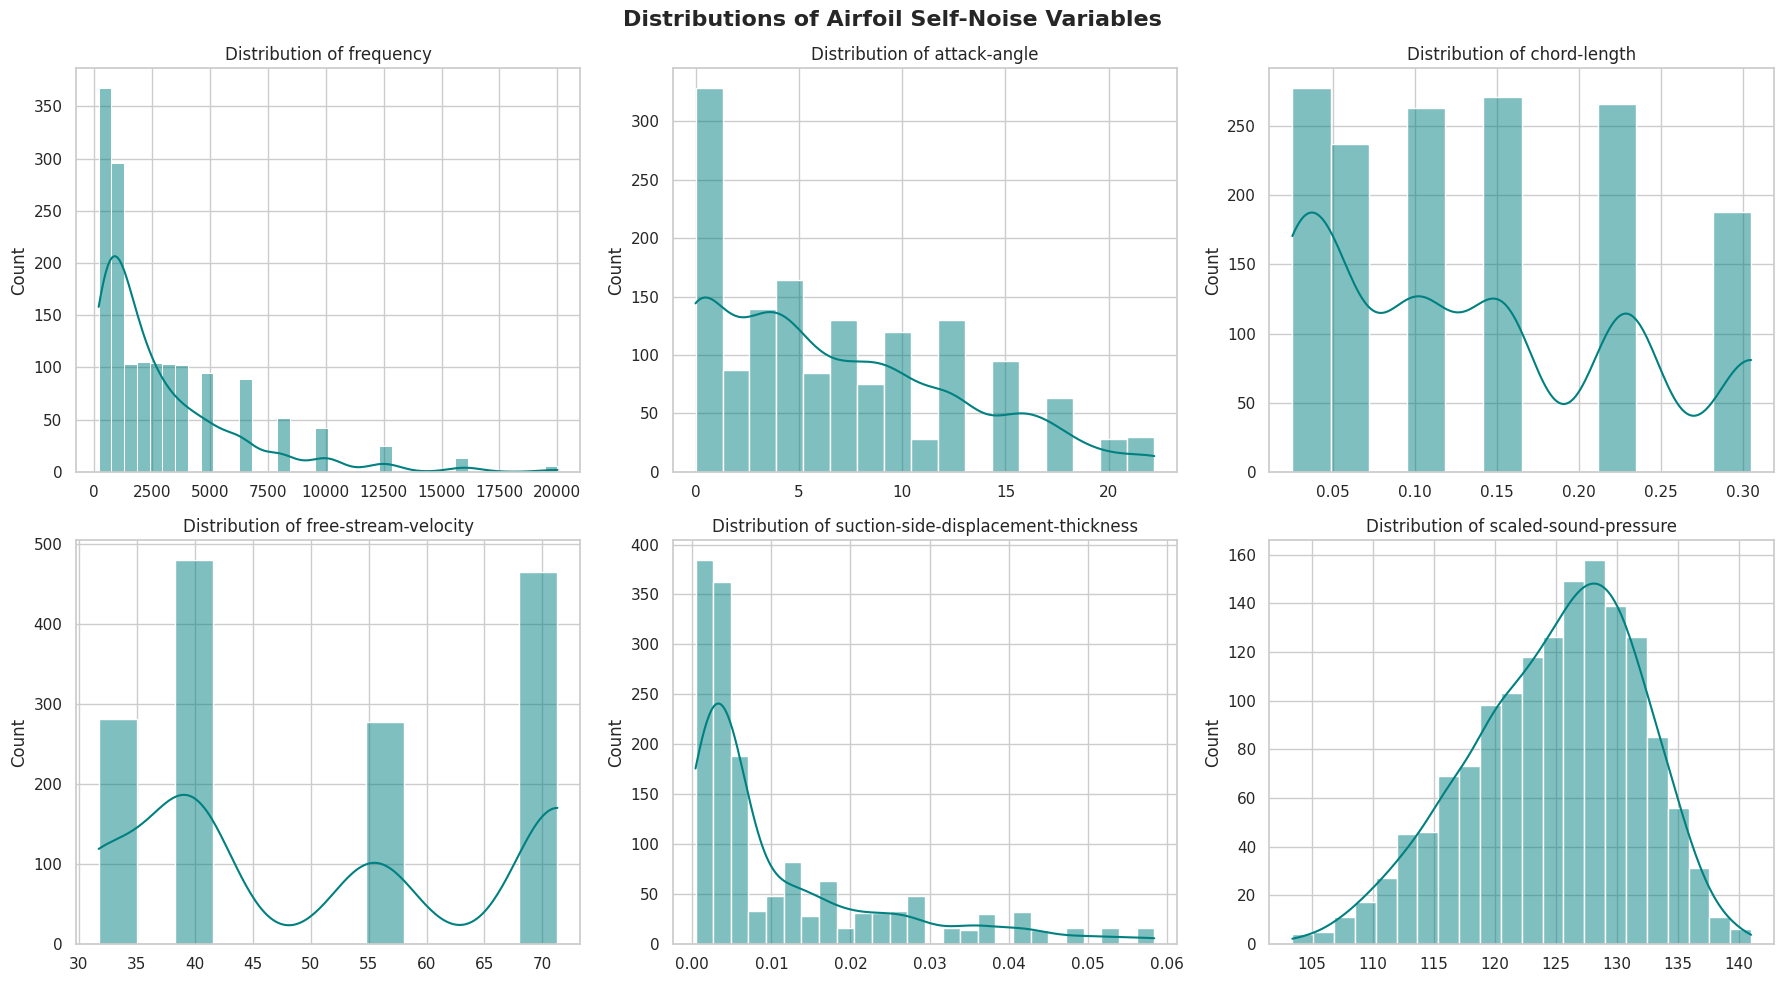

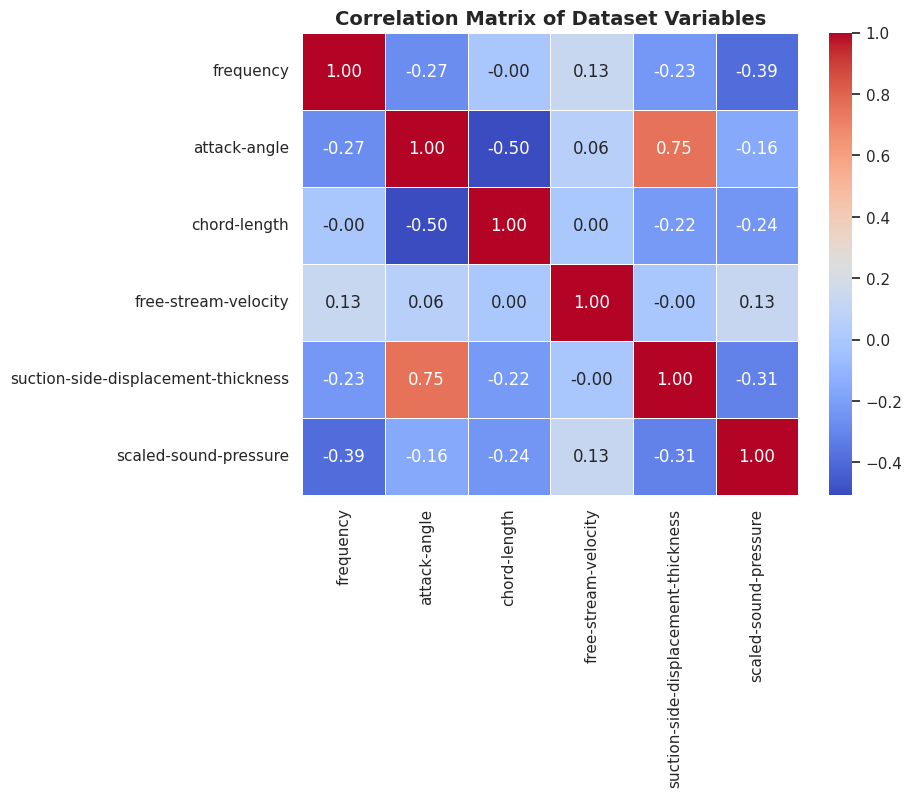

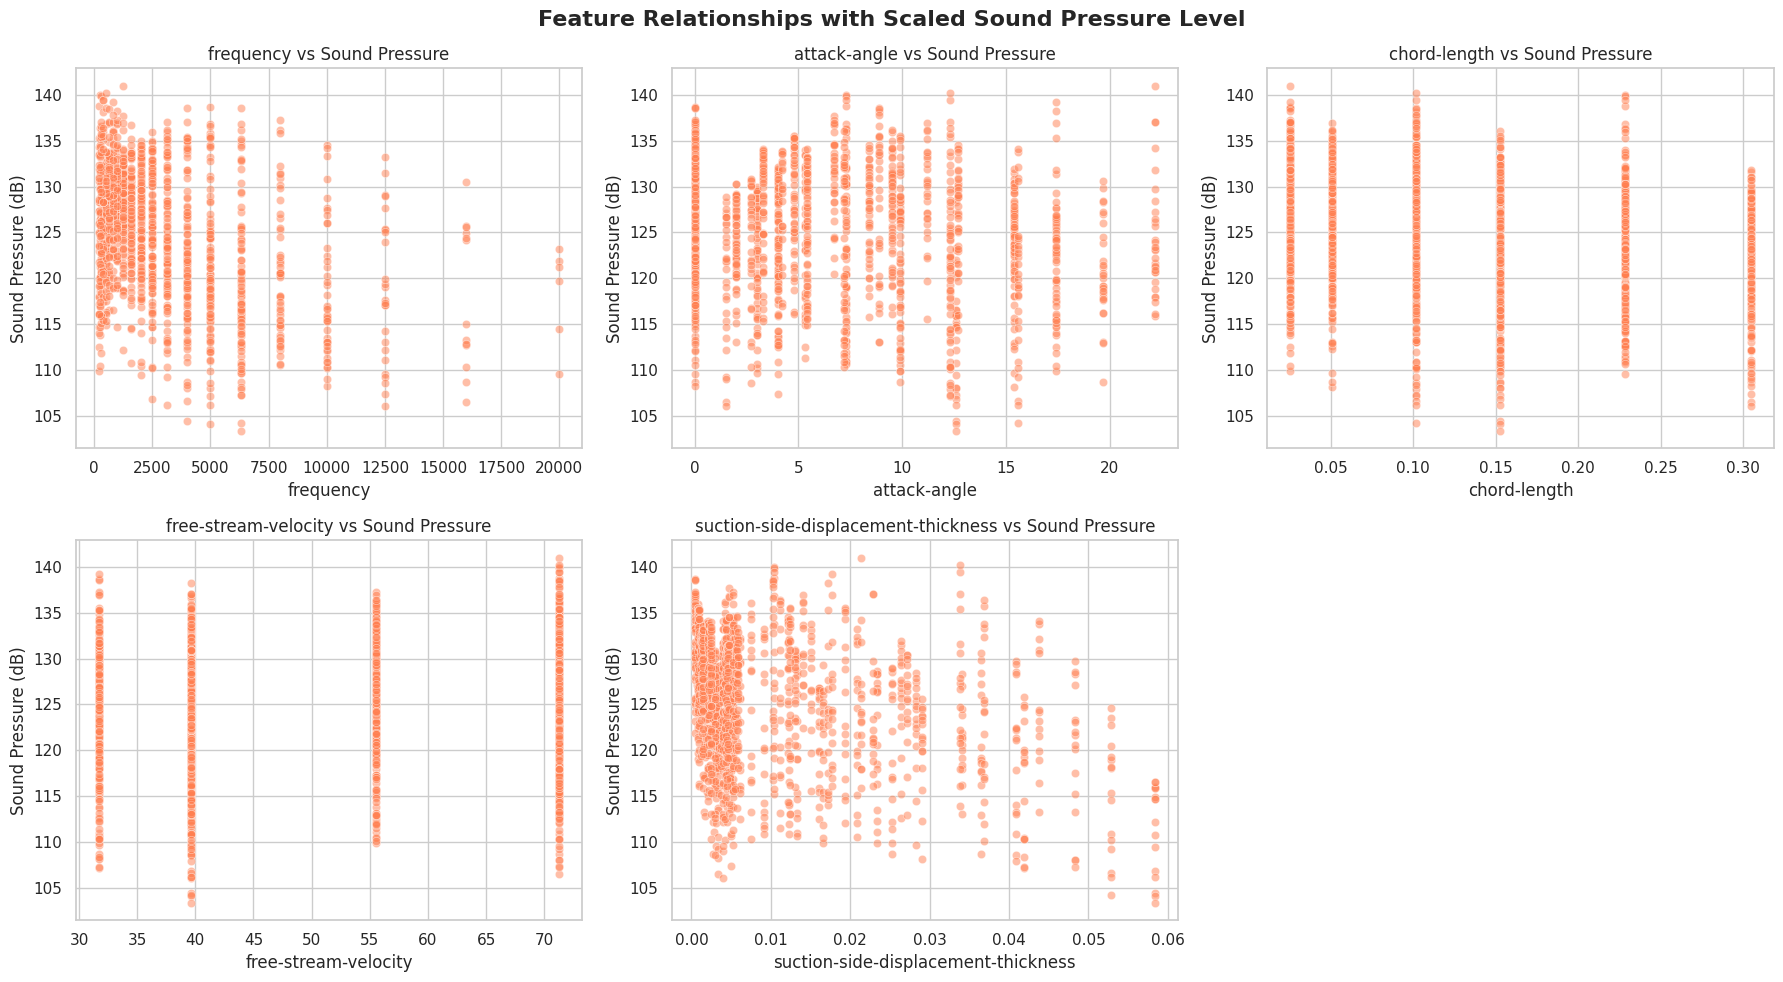

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Combine features and targets for visualization
df_vis = pd.concat([X, y], axis=1)

# Set up the plotting style
sns.set_theme(style='whitegrid')

# 1. Distribution of Features and Target
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Distributions of Airfoil Self-Noise Variables', fontsize=16, fontweight='bold')

columns = df_vis.columns
for i, col in enumerate(columns):
    ax = axes[i // 3, i % 3]
    sns.histplot(df_vis[col], kde=True, ax=ax, color='teal')
    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel('')

plt.tight_layout()
plt.show()

# 2. Correlation Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df_vis.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Dataset Variables', fontsize=14, fontweight='bold')
plt.show()

# 3. Relationships with Target (Scaled Sound Pressure)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Feature Relationships with Scaled Sound Pressure Level', fontsize=16, fontweight='bold')

feature_cols = X.columns
for i, col in enumerate(feature_cols):
    ax = axes[i // 3, i % 3]
    sns.scatterplot(data=df_vis, x=col, y='scaled-sound-pressure', ax=ax, alpha=0.5, color='coral')
    ax.set_title(f'{col} vs Sound Pressure')
    ax.set_ylabel('Sound Pressure (dB)')

# Hide the unused subplot
axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

In [51]:
import torch
from sklearn.preprocessing import StandardScaler

device = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
print(f"Using {device} device")

# Scale features using StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convert to PyTorch tensors
X_tensor = torch.tensor(X_scaled, dtype=torch.double)
y_tensor = y.to(dtype=torch.double)

# Loaders for X,y
generator = torch.Generator().manual_seed(42)
dset = torch.utils.data.TensorDataset(X_tensor, y_tensor)
train_dset, val_dset = torch.utils.data.random_split(dset, [0.7, 0.3], generator=generator)

Using cuda device


In [53]:
train_data_loader = torch.utils.data.DataLoader(train_dset, batch_size=32, shuffle=True)
val_data_loader = torch.utils.data.DataLoader(val_dset, batch_size=32, shuffle=True)

fcnn_model = torch.nn.Sequential(
    torch.nn.Linear(5, 32),
    torch.nn.ReLU(),
    torch.nn.Linear(32, 16),
    torch.nn.ReLU(),
    torch.nn.Linear(16, 1),
).to(device).to(dtype=torch.double)

# Init weights using He (Kaiming) because we use ReLU activation
for layer in fcnn_model:
    if isinstance(layer, torch.nn.Linear):
        torch.nn.init.kaiming_normal_(layer.weight)
        torch.nn.init.zeros_(layer.bias)

loss_fn = torch.nn.MSELoss()
optimizer = torch.optim.Adam(fcnn_model.parameters(), lr=0.001)

for epoch in range(200):
    fcnn_model.train()
    loss_train = 0
    for X_batch, y_batch in train_data_loader:
        X_batch = X_batch.to(device, non_blocking=True)
        y_batch = y_batch.to(device, non_blocking=True)

        optimizer.zero_grad()
        y_pred = fcnn_model(X_batch)
        loss = loss_fn(y_pred, y_batch)
        loss.backward()
        optimizer.step()
        loss_train += loss.item() * len(X_batch)

    loss_train /= len(train_dset)

    # Validation loop with no_grad and no optimizer updates
    fcnn_model.eval()
    loss_val = 0
    with torch.no_grad():
        for X_batch, y_batch in val_data_loader:
            X_batch = X_batch.to(device, non_blocking=True)
            y_batch = y_batch.to(device, non_blocking=True)
            y_pred = fcnn_model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            loss_val += loss.item() * len(X_batch)

    loss_val /= len(val_dset)

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:02d} | Train MSE: {loss_train:.4f} | Val MSE: {loss_val:.4f}")

Epoch 01 | Train MSE: 15312.2714 | Val MSE: 15095.6923
Epoch 05 | Train MSE: 11515.9589 | Val MSE: 10718.3020
Epoch 10 | Train MSE: 2596.2136 | Val MSE: 2098.2490
Epoch 15 | Train MSE: 545.8371 | Val MSE: 538.8035
Epoch 20 | Train MSE: 384.0868 | Val MSE: 423.2223
Epoch 25 | Train MSE: 324.4025 | Val MSE: 366.6857
Epoch 30 | Train MSE: 281.0707 | Val MSE: 321.2352
Epoch 35 | Train MSE: 244.8435 | Val MSE: 282.5720
Epoch 40 | Train MSE: 214.9327 | Val MSE: 249.2571
Epoch 45 | Train MSE: 189.8870 | Val MSE: 220.2663
Epoch 50 | Train MSE: 167.1405 | Val MSE: 194.9267
Epoch 55 | Train MSE: 147.0867 | Val MSE: 171.7229
Epoch 60 | Train MSE: 128.9558 | Val MSE: 150.6711
Epoch 65 | Train MSE: 112.4706 | Val MSE: 130.5272
Epoch 70 | Train MSE: 97.2731 | Val MSE: 112.6559
Epoch 75 | Train MSE: 83.3883 | Val MSE: 96.1207
Epoch 80 | Train MSE: 71.0155 | Val MSE: 81.5883
Epoch 85 | Train MSE: 60.1271 | Val MSE: 69.1798
Epoch 90 | Train MSE: 51.3242 | Val MSE: 58.9606
Epoch 95 | Train MSE: 44.4280 

In [54]:
import torch

def calculate_r2(model, data_loader, dataset_len):
    model.eval()
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch = X_batch.to(device, non_blocking=True)
            y_batch = y_batch.to(device, non_blocking=True)
            preds = model(X_batch)
            all_preds.append(preds.cpu())
            all_targets.append(y_batch.cpu())

    all_preds = torch.cat(all_preds, dim=0)
    all_targets = torch.cat(all_targets, dim=0)

    # Calculate R-squared
    target_mean = torch.mean(all_targets)
    ss_tot = torch.sum((all_targets - target_mean) ** 2)
    ss_res = torch.sum((all_targets - all_preds) ** 2)
    r2 = 1 - (ss_res / ss_tot)
    return r2.item()

train_r2 = calculate_r2(fcnn_model, train_data_loader, len(train_dset))
val_r2 = calculate_r2(fcnn_model, val_data_loader, len(val_dset))

print(f"Training R² Score: {train_r2:.4f}")
print(f"Validation R² Score: {val_r2:.4f}")

Training R² Score: 0.7417
Validation R² Score: 0.6834
